
**Creando redes neuronales con Keras**

Tensorflow es uno de los frameworks más usados para la simulación de redes neuronales artificiales y de diferentes arquitecturas de deep learning.

En este notebook haremos uso de la herramienta keras que viene incorporada en este framework.

Keras se puede entender como una interface que permite crear de manera amigable redes neuronales artificiales usando como backend las funciones base de Tensorflow.



**Importación de la diferentes librerías**


Inicialmente importamos liberías necesarias para este ejemplo

In [1]:
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt


**Definición de los datos de entrenamiento**

Para entrenar redes neuronales, lo primero es tener los datos que se van a usar para entrenarala

En este caso, la meta en estrenar una red neuronal que "aprenda" la función lógica and

In [2]:
# Se crean las variables de entrada y salida para entrenar la red neuronal
x_train =np.array([[0,0],[0,1],[1,0],[1,1]])
y_train =np.array([[0],[0],[0],[1]])
print(x_train)
print(y_train)

[[0 0]
 [0 1]
 [1 0]
 [1 1]]
[[0]
 [0]
 [0]
 [1]]


**Creación de la red neuronal monocapa**

Usando el método "sequential" de Keras, podemos armar una red neuronal capa a capa de manera similar a la que un pastelero hace un pastel de varios pisos o un cocinero hace lasaña. Las deferentes capas se van añadiendo de manera secuencial

In [3]:

# Creación de una red monocapa con función de activación sigmoidal
modelo = keras.models.Sequential()
modelo.add(keras.layers.Dense(1,input_shape=(2,),activation='sigmoid'))

# Este comando, nos permite conocer la cantidad total de parámetros que tiene la red neuronal
modelo.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 1)                 3         
                                                                 
Total params: 3
Trainable params: 3
Non-trainable params: 0
_________________________________________________________________


In [4]:
# Con el modelo creado, lo compilamos. En este paso se define el método de entrenamiento
# y las métricas que vamos a usar para este proceso
modelo.compile('rmsprop','mse',metrics=['accuracy'])
# Con el modelo compilado, procedemos a entrenarlo
historia=modelo.fit(x_train,y_train,epochs=5000,verbose=0)
# Finalmente calculamos las métricas del modelo ya entrenado
modelo.evaluate(x_train,y_train)


1/1 [==============================] - 0s 144ms/step - loss: 0.0191 - accuracy: 1.0000


[0.01907554268836975, 1.0]

**Visualización de la evolucion de la pérdida y de la precisión**

Graficamos la evolución de la pérdida del modelo

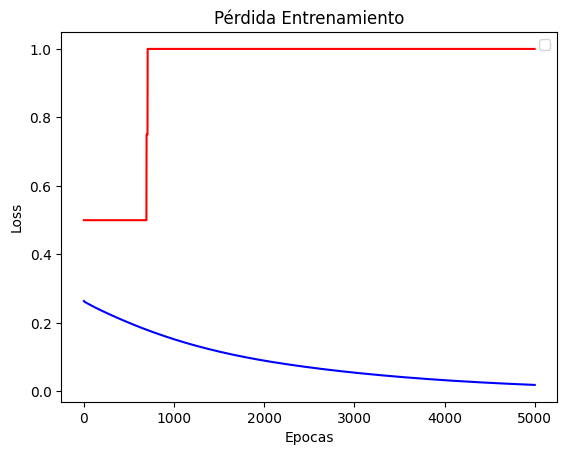

In [5]:
perdida_train = historia.history['loss']
precision_train = historia.history['accuracy']
epocas = range(1, len(perdida_train) + 1)
plt.plot(epocas, perdida_train, 'b', precision_train, 'r')
plt.title('Pérdida Entrenamiento')
plt.xlabel('Epocas')
plt.ylabel('Loss')
plt.legend()
plt.show()

**Cálculo de la salida del modelo**

Con el modelo ya entrenado, calculamos su salida con las entradas usadas en el proceso de entrenamiento

In [6]:
# Uso de la opción predict del modelo para calcular su salida cuando se le proporciona
# unos valores a la entrada
y_predic=modelo.predict(x_train)
print(y_predic)

1/1 [==============================] - 0s 74ms/step
[[0.00677636]
 [0.15866517]
 [0.15866517]
 [0.83904356]]


**Extracción de las matrices de pesos y bias**

Con el siguiente código podemos obtener los valores de las conexiones de la red ya entrenada


In [7]:
CapaProcesamiento = modelo.layers[0]
weightsco, biasesco = CapaProcesamiento.get_weights()
print(weightsco)
print(biasesco)

[[3.3193223]
 [3.3193223]]
[-4.987516]


**Creación de una red neuronal con una capa oculta**

Usando el método "sequential" de Keras, adicionaremos otra capa a la red neuronal para tener una res multicapa con una capa oculta y una capa de salida

In [8]:
# Creación del modelo secuencial con una capa oculta y una capa de salida
modelo2 = keras.models.Sequential()
modelo2.add(keras.layers.Dense(5,input_shape=(2,),activation='tanh'))
modelo2.add(keras.layers.Dense(1,activation='sigmoid'))
# Verificar la cantidad de parámetros que tiene el modelo
modelo2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1 (Dense)             (None, 5)                 15        
                                                                 
 dense_2 (Dense)             (None, 1)                 6         
                                                                 
Total params: 21
Trainable params: 21
Non-trainable params: 0
_________________________________________________________________


**Entreanamiento de la red multicapa**

In [9]:
modelo2.compile('rmsprop','mse',metrics=['accuracy'])
historia2=modelo2.fit(x_train,y_train,epochs=5000,verbose=0)
modelo2.evaluate(x_train,y_train)

1/1 [==============================] - 0s 121ms/step - loss: 1.1294e-05 - accuracy: 1.0000


[1.1293681382085197e-05, 1.0]

**Graficación de la pérdida y la precisión de la red multicapa**

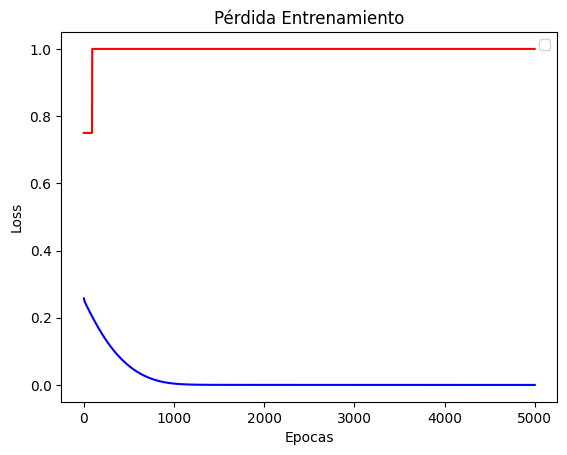

In [10]:
perdida_train = historia2.history['loss']
precision_train = historia2.history['accuracy']
epocas = range(1, len(perdida_train) + 1)
plt.plot(epocas, perdida_train, 'b', precision_train, 'r')
plt.title('Pérdida Entrenamiento')
plt.xlabel('Epocas')
plt.ylabel('Loss')
plt.legend()
plt.show()

**Calculo de la salida de la red multicapa**

In [11]:
# Nótese que la salida de esta red es más parecida a la salida deseada
y_predic=modelo2.predict(x_train)
print(y_predic)

1/1 [==============================] - 0s 55ms/step
[[7.4901427e-06]
 [3.5167262e-03]
 [3.4918908e-03]
 [9.9545974e-01]]


**Extracción de la matrices de los pesos y bias de la capa oculta**

In [12]:
CapaOculta = modelo2.layers[0]
weightsco, biasesco =CapaOculta.get_weights()
print(weightsco)
print(biasesco)

[[-0.7805032  -1.6501107   1.1281245   0.6865457   1.174803  ]
 [-1.4701062  -0.6544764   1.0918701   1.4152168   0.94396925]]
[ 1.5654956  1.5516614 -1.5847713 -1.4440347 -1.504803 ]


**Extracción de la matrices de los pesos y bias de la capa de salida**

In [13]:
CapaSalida = modelo2.layers[1]
weightscs, biasescs = CapaSalida.get_weights()
print(weightscs)
print(biasescs)

[[-2.4108403]
 [-2.5051985]
 [ 2.5638657]
 [ 1.9110049]
 [ 2.1024964]]
[-1.3315781]
